# Spin-boson model: comparing three simulation approaches

This notebook reproduces the headline weak-coupling comparison from the thesis (Fig. 4.2): a single qubit coupled to an Ohmic bath, simulated three ways:

1. **Markov approximation** — analytical baseline, valid in the weak-coupling limit.
2. **Surrogate Hamiltonian** — N bath modes sampled near resonance, propagated with QuTiP.
3. **Chain mapping** — bath unitarily mapped to a 1D chain, propagated as an MPS via TEBD (TeNPy).

All three should agree at weak coupling. Strong coupling (set `alpha = 0.1`) breaks the Markov approximation while leaving chain mapping intact — that's the headline result.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import matplotlib.pyplot as plt
import qutip as qt

from src.spin_boson import SpinBosonParams
from src.markov import evolve_markov
from src.surrogate import evolve_surrogate
from src.chain_mapping import evolve_chain_mapping

In [2]:
# Weak coupling — Markov approximation should be valid.
p = SpinBosonParams(omega0=1.0, omega_c=2.0, alpha=0.001, s=1.0)
t_max = 20.0
psi_sys0 = qt.basis(2, 0)  # qubit in |up>
rho0 = psi_sys0 * psi_sys0.dag()

In [3]:
result_markov = evolve_markov(p, t_max, rho0)

In [4]:
result_surrogate, expect_surrogate, bath_freqs = evolve_surrogate(
    N=15, n_levels=2, p=p, t_max=t_max, psi_sys0=psi_sys0
)

10.0%. Run time:   0.22s. Est. time left: 00:00:00:01


20.0%. Run time:   0.49s. Est. time left: 00:00:00:01


30.0%. Run time:   0.82s. Est. time left: 00:00:00:01


40.0%. Run time:   1.20s. Est. time left: 00:00:00:01


50.1%. Run time:   1.58s. Est. time left: 00:00:00:01


...

70.1%. Run time:   2.35s. Est. time left: 00:00:00:01


80.1%. Run time:   2.74s. Est. time left: 00:00:00:00


90.1%. Run time:   3.12s. Est. time left: 00:00:00:00


100.0%. Run time:   3.49s. Est. time left: 00:00:00:00


Total run time:   3.49s


In [5]:
data_chain, _ = evolve_chain_mapping(L=100, p=p, t_max=t_max, chi_max=50)

/Users/isabellemcentee/Desktop/oqs-simulation/.venv/lib/python3.14/site-packages/tenpy/networks/mps.py:1629: UserWarning: unit_cell_width is a new argument for MPS and similar classes. It is optional for now, but will become mandatory in a future release. The default value (unit_cell_width=len(sites)) is correct, iff the lattice is a Chain. For other lattices, it is incorrect. It is used for dipolar charges and correlation_function2.
  super().__init__(sites, bc, unit_cell_width)


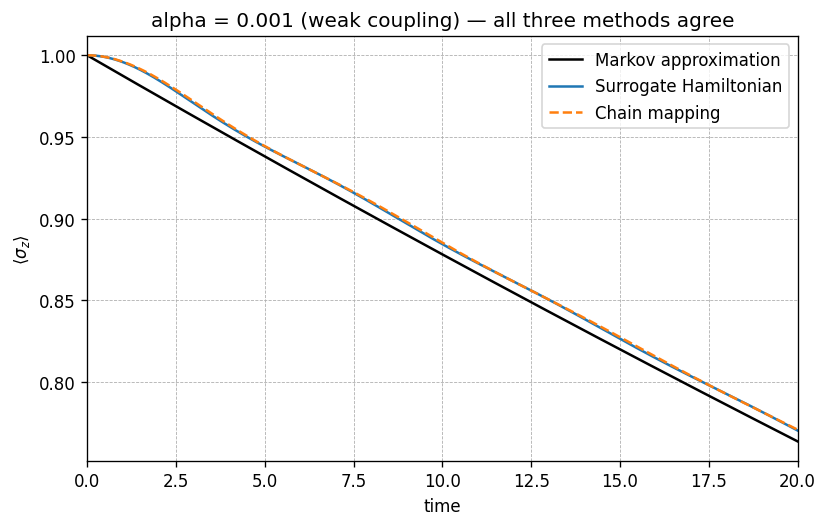

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
ax.plot(result_markov.times, result_markov.expect[2], 'k-', label='Markov approximation')
ax.plot(result_surrogate.times, expect_surrogate['sz'], label='Surrogate Hamiltonian')
ax.plot(data_chain['t'], data_chain['sz'][:, 0], '--', label='Chain mapping')
ax.set_xlabel('time')
ax.set_ylabel(r'$\langle \sigma_z \rangle$')
ax.set_xlim(0, t_max)
ax.grid(True, linestyle='--', linewidth=0.5)
ax.legend()
ax.set_title(f'alpha = {p.alpha} (weak coupling) — all three methods agree')
fig.tight_layout()

## Strong coupling — where the Markov approximation breaks

Set `alpha = 0.1` and the Markov approximation is no longer valid: it predicts a smooth exponential decay to zero, but the *true* dynamics show damped oscillations and a finite steady state, both signatures of memory effects in the bath. The chain mapping and surrogate Hamiltonian capture this; Markov misses it entirely.

Reproduces the thesis Fig. 4.4.

In [7]:
p_strong = SpinBosonParams(omega0=1.0, omega_c=2.0, alpha=0.1, s=1.0)

result_markov_s = evolve_markov(p_strong, t_max, rho0)
result_surrogate_s, expect_surrogate_s, _ = evolve_surrogate(
    N=15, n_levels=2, p=p_strong, t_max=t_max, psi_sys0=psi_sys0
)
data_chain_s, _ = evolve_chain_mapping(L=100, p=p_strong, t_max=t_max, chi_max=50)

10.0%. Run time:   0.30s. Est. time left: 00:00:00:02


20.0%. Run time:   0.63s. Est. time left: 00:00:00:02


30.0%. Run time:   0.99s. Est. time left: 00:00:00:02


40.0%. Run time:   1.37s. Est. time left: 00:00:00:02


50.1%. Run time:   1.78s. Est. time left: 00:00:00:01


...

80.1%. Run time:   3.00s. Est. time left: 00:00:00:00


90.1%. Run time:   3.40s. Est. time left: 00:00:00:00


100.0%. Run time:   3.80s. Est. time left: 00:00:00:00


Total run time:   3.80s


  super().__init__(sites, bc, unit_cell_width)



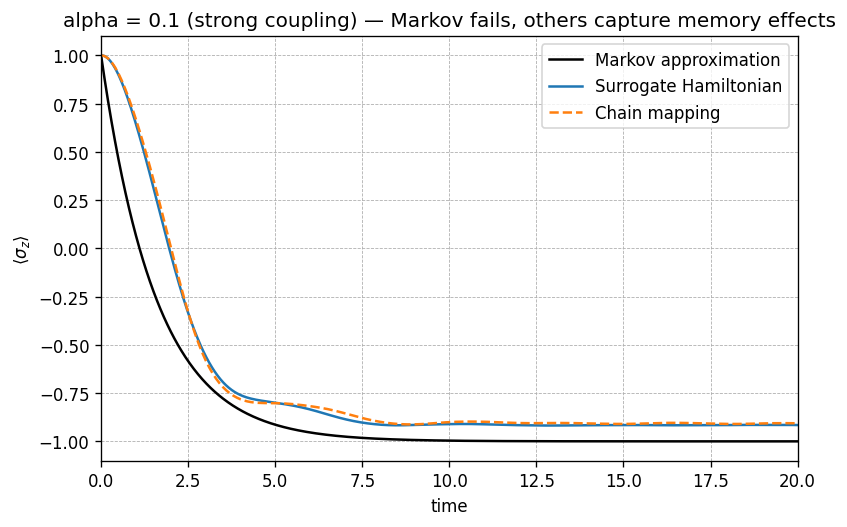

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5), dpi=120)
ax.plot(result_markov_s.times, result_markov_s.expect[2], 'k-', label='Markov approximation')
ax.plot(result_surrogate_s.times, expect_surrogate_s['sz'], label='Surrogate Hamiltonian')
ax.plot(data_chain_s['t'], data_chain_s['sz'][:, 0], '--', label='Chain mapping')
ax.set_xlabel('time')
ax.set_ylabel(r'$\langle \sigma_z \rangle$')
ax.set_xlim(0, t_max)
ax.grid(True, linestyle='--', linewidth=0.5)
ax.legend()
ax.set_title(f'alpha = {p_strong.alpha} (strong coupling) — Markov fails, others capture memory effects')
fig.tight_layout()